# Stiffness a.k.a "what makes your simulation slow"

An ODE problem is stiff when an **explicit time step is dictated by stability requirements**, not accuracy requirements.
Roughly speaking, some processes in the system are moving on **different time scales** than others.
Smaller time steps mean more computations and **therefore longer simulations**.

**Chromatography models are generally stiff**: they often contain processes on very different time scales, such as convection and pore diffusion.

## Stiffness: simple example with two time scales

Take **one axial cell** of a chromatography column, a slice of bed with the particles in it, and keep only two things: material convected into the slice, and material transferred through the film into those particles. For the column used later in this notebook those two run at

$$\lambda_\text{slow} = -1.2\ \mathrm{s^{-1}}\ \text{(convection across one cell)}, \qquad \lambda_\text{fast} = -1135\ \mathrm{s^{-1}}\ \text{(film transfer)}.$$

Written as a coupled linear system, so that neither component belongs to one scale alone:

$$
\frac{\mathrm{d}}{\mathrm{d}t}
\begin{pmatrix} y_1 \\ y_2 \end{pmatrix}
=
\begin{pmatrix} -568.2 & 567.0 \\ 567.0 & -568.2 \end{pmatrix}
\begin{pmatrix} y_1 \\ y_2 \end{pmatrix},
\qquad
\begin{pmatrix} y_1(0) \\ y_2(0) \end{pmatrix} = \begin{pmatrix} 1 \\ 0 \end{pmatrix}
$$

Nothing about those four numbers looks dramatic. The analytical solution shows what they mean:

$$
y(t) \;=\; \underbrace{\tfrac{1}{2}\, e^{-1.2\,t} \begin{pmatrix} 1 \\ 1 \end{pmatrix}}_{\text{slow: seconds}}
\;+\; \underbrace{\tfrac{1}{2}\, e^{-1135\,t} \begin{pmatrix} 1 \\ -1 \end{pmatrix}}_{\text{fast: milliseconds}}
$$

**One process decays over seconds, the other over milliseconds**, a factor of **946** between them, both in the same model.
The next cell shows the solution: After roughly five milliseconds the fast one is gone, and what is left is a plain exponential decay.

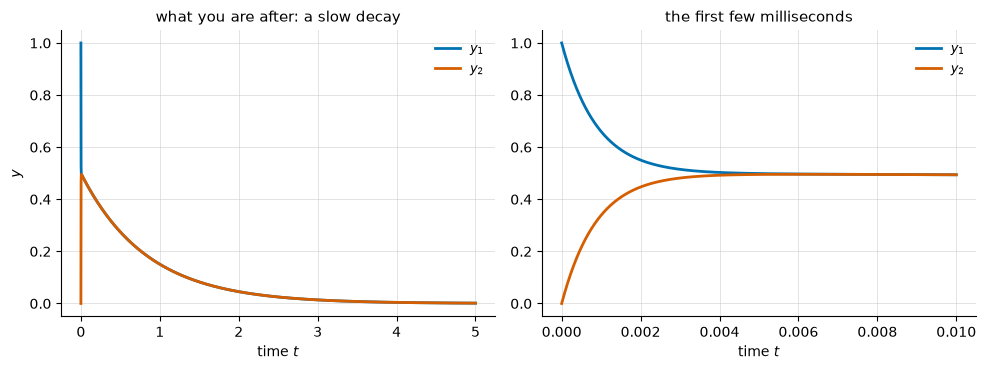

In [2]:
import numpy as np
import utility.stiffness_demos as demos

demos.plot_two_scale_solution(t_end=5.0, zoom_end=0.01);

### Explicit vs. Implicit time integration

The two simplest implicit and explicit time integration methods:

- **explicit Euler**, $\;y_{n+1} = y_n + h\,A\,y_n\;$ —> explicit formulation: the new value is written down from the old one.
- **implicit Euler**, $\;(I - h\,A)\,y_{n+1} = y_n\;$ —> a system of equations has to be solved for every single step.

Both require a time step $h > 0$.
From the solution perspective, we care about the slow scale, which takes about $0.8\ \mathrm{s}$ to act, so a step of $h = 0.1$ follows it with fifty steps across the whole curve.

We test both methods with different time step sizes and gather their accuracy in the table below.

In [3]:
from ipywidgets import interact

show_euler = demos.make_time_step_explorer()

interact(show_euler, **show_euler.sliders);

interactive(children=(SelectionSlider(continuous_update=False, description='time step', options=(('0.2', 0.2),…

### What is happening here

- At coarse time steps, the implicit method is less accurate and improves with refinement of h
- The explicit method however blows up, errors accumulate towards infinity
- Only at the fine time step, explicit time stepping is suddenly accurate. There is no inaccurate range.

> **An implicit method chooses its step size for accuracy. An explicit method has its step size dictated by stability.**

The **fast mode per step** is the factor by which one step multiplies the fast component. For explicit Euler it is $|1 + h\lambda_\text{fast}|$, which passes 1 at $h = 2/|\lambda_\text{fast}| = 1.76\ \mathrm{ms}$; for implicit Euler it is $1/|1 - h\lambda_\text{fast}|$, which is below 1 for every $h$ there is.

The **fastest** process in the system dictates the explicit time step, whether its important or not. Here, the fast process is over after five milliseconds, and it still dictates the step size for the remaining five seconds.

<details>
<summary><b>Click to learn more about stability</b></summary>

The behaviour of a linear system is governed by the **eigenvalues** of its matrix, here

$$\lambda_{\text{slow}} = -1.2\ \mathrm{s^{-1}}, \qquad \lambda_{\text{fast}} = -1135\ \mathrm{s^{-1}},$$

which are exactly the two decay rates in the analytical solution above. One step of a method multiplies each eigen-component by an amplification factor $R(z)$, where $z = h\lambda$ is the **scaled eigenvalue**:

$$R_{\text{explicit}}(z) = 1 + z, \qquad\qquad R_{\text{implicit}}(z) = \frac{1}{1-z}.$$

A component stays bounded if $|R(z)| \le 1$, and the set of all $z$ for which that holds is the method's **stability region**.

For explicit Euler, $|1 + z| \le 1$ is a disk of radius one around $-1$, so we need $-2 < h\lambda < 0$. With $\lambda = -1135\ \mathrm{s^{-1}}$ that is $h < 1.76\ \mathrm{ms}$, and our $h = 0.1$ is **fifty-seven times** too large: the fast component gets multiplied by $1 - 113.5 = -112.5$ every step. Runge-Kutta 4 has a larger region, but it is still bounded — no explicit method escapes this.

For implicit Euler, $|1/(1-z)| \le 1$ holds for *every* $z$ in the left half plane. Every decaying process is stable at every step size. That is what you buy with the solve in every step.

<img src="data/02b_stiffness/stability_regions.png" width="860" alt="stability regions of explicit and implicit methods">

The ratio $|\lambda_{\text{fast}}| / |\lambda_{\text{slow}}| = 946$ is sometimes called the **stiffness ratio**. It is a crude indicator, but it carries the right intuition: the further apart the time scales, the wider the gap between the step size your result needs and the step size your method is allowed.

</details>

### What it costs to be stable

The implicit time integration has to solve the system 
$\;(I - h\,A)\,y_{n+1} = y_n\;$
meaning the matrix $(I - h\,A)$ has to be inverted.
Depending on the size and nonlinearity of the matrix, this becomes computationally expensive.
> **That is the trade.** The stability constraint is removed, and in exchange every step becomes expensive.

## What this means for CADET
1. **time integration must be implicit** to escape excessive explicit time step stability constraints
2. implicit integration is only **limited by accuracy, not stability** / stiffness
3. but implicit **time integration costs** a lot more per time step because a **nonlinear system must be solved**
4. also **strong gradients** in the solution often require more time steps even for implicit time integration

> **In CADET, stiffness never breaks your simulation but bills you for it.**

> **The computational time is mostly spent on solving the nonlinear system Jacobian, which becomes more expensive the larger the matrix is and the more connected and nonlinear the equations are.**

## Stiffness in a CADET simulation
- the following is a stiff chroimatography simulation with a GRM and different time scales for film-, pore diffusion and velocity (see table below)
- An explicit solver is forced to take small time steps here, similar to a CADET simulation with absolute time integration tolerance of around $1e-10$
- CADET however can take bigger time steps using $abstol=1e-3$ and still get an accurate result (NRMSE $0.3\%$)
- The difference is 220 vs 1300 time steps taken, which saves us a lot of compute

In [3]:
# Rendered once and stored
#
#   import utility.column_animation as column_animation
#   column_animation.make_abstol_animation(force=True)
from IPython.display import Video

Video('data/02b_stiffness/column_abstol.webm', embed=False, width=900,
      html_attributes='controls loop autoplay muted playsinline')

# Does stiffness impact CADET at all?

Lets try to challenge CADET with stiff problems.
How can we construct stiff problems?

# Putting a number on "fast" and "slow"

So far "fast" and "slow" have been adjectives.
From here on they are numbers, and the number is a **rate in $1/\mathrm{s}$**: bigger means faster.
You get one for every process by dividing its coefficient by the (discretized) **length or surface it acts over**:

The values below are the ones in the video above: 120 axial cells over $0.1\ \mathrm{m}$, particles of $45\ \mathrm{\mu m}$ resolved in 16 radial shells, $\varepsilon = 0.37$.

| process | discretized rate | this simulation |
|---|---|---|
| convection | $u_\mathrm{int} / \Delta z$ | $10^{-3} / 8.33\cdot10^{-4}$ = $\mathbf{1.2\ s^{-1}}$ |
| dispersion | $D_\mathrm{ax} / (\Delta z)^{2}$ | $2\cdot10^{-8} / (8.33\cdot10^{-4})^{2}$ = $\mathbf{0.029\ s^{-1}}$ |
| pore diffusion | $D_p / (\Delta r)^{2}$ | $3\cdot10^{-10} / (2.81\cdot10^{-6})^{2}$ = $\mathbf{38\ s^{-1}}$ |
| film mass transfer | $3 k_f / R_p \cdot (1-\varepsilon)/\varepsilon$ | $3\cdot10^{-2} / 4.5\cdot10^{-5} \cdot 0.63/0.37$ = $\mathbf{1135\ s^{-1}}$ |
| binding kinetics | $k_a c + k_d$ | equilibrium |

<details><summary><b>Click to learn more about the table</b></summary>
**Binding has no rate in this simulation.** It is a *rapid equilibrium* isotherm, $q = K c$ with $K = 1.5$, which is not a differential equation at all: it is an algebraic constraint, and it is why CADET solves a DAE rather than an ODE. An algebraic equation is the limit of an infinitely fast rate, so in the table above it sits at $\infty$ &mdash; and costs nothing, because an implicit solver does not care. Switch the same isotherm to kinetic, $k_a = 0.15\ \mathrm{s^{-1}}$ and $k_d = 0.1\ \mathrm{s^{-1}}$ (the variant used in the sweeps further down, chosen to keep $K = k_a/k_d = 1.5$), and the rate becomes $k_a c + k_d = \mathbf{0.25\ s^{-1}}$ at $c = 1\ \mathrm{mol/m^3}$: slower than convection, and therefore invisible in the step count.

Two things are worth reading off that table.

**The span is five orders of magnitude**, from $0.022\ \mathrm{s^{-1}}$ for the feature you actually plot to $1135\ \mathrm{s^{-1}}$ for the film. That ratio *is* the stiffness. Explicit Euler would be capped at $h \le 2/1135 = 1.76\ \mathrm{ms}$, so about $2.8\cdot10^{5}$ steps for the 500 s run &mdash; against the 1296 and 221 steps the implicit solver actually took in the two lanes of the video.

**Most of those rates are set by your grid.** The particle's own diffusion rate is $D_p/R_p^{2} = 0.15\ \mathrm{s^{-1}}$, slower than convection across a cell. Cutting it into 16 shells makes $\Delta r = R_p/16$ and the rate $16^2 = 256$ times larger, which is how a physically sluggish process ends up at $38\ \mathrm{s^{-1}}$. Refining a diffusive direction costs you the square of the refinement; refining the axial grid raises the convective rate linearly and the dispersive one quadratically. Only the film rate is pure physics here, and it is the one you cannot do anything about.
</details>

### The rule

> **Find the largest rate in the table and compare it with the magnitude and time window of the result you want to look at.** Processes that you cannot see in the result, e.g. chromatogram with error tolerance, are what cost you.

## Where those rates actually sit

What the integrator reacts to is an **eigenvalue** of the ODE Jacobian.
All eigenvalues scaled by the time step size ($z = h\lambda$) must lay inside the **stability region** of the time integration.

So the question for a chromatography model is simply: **where in that stability region do chromatographic equations land?**

### The five regions IDAS switches between

IDAS does not run one method. It runs backward differentiation formulas of order one to five and changes the order as it goes, so "the stability region" above is really five of them.

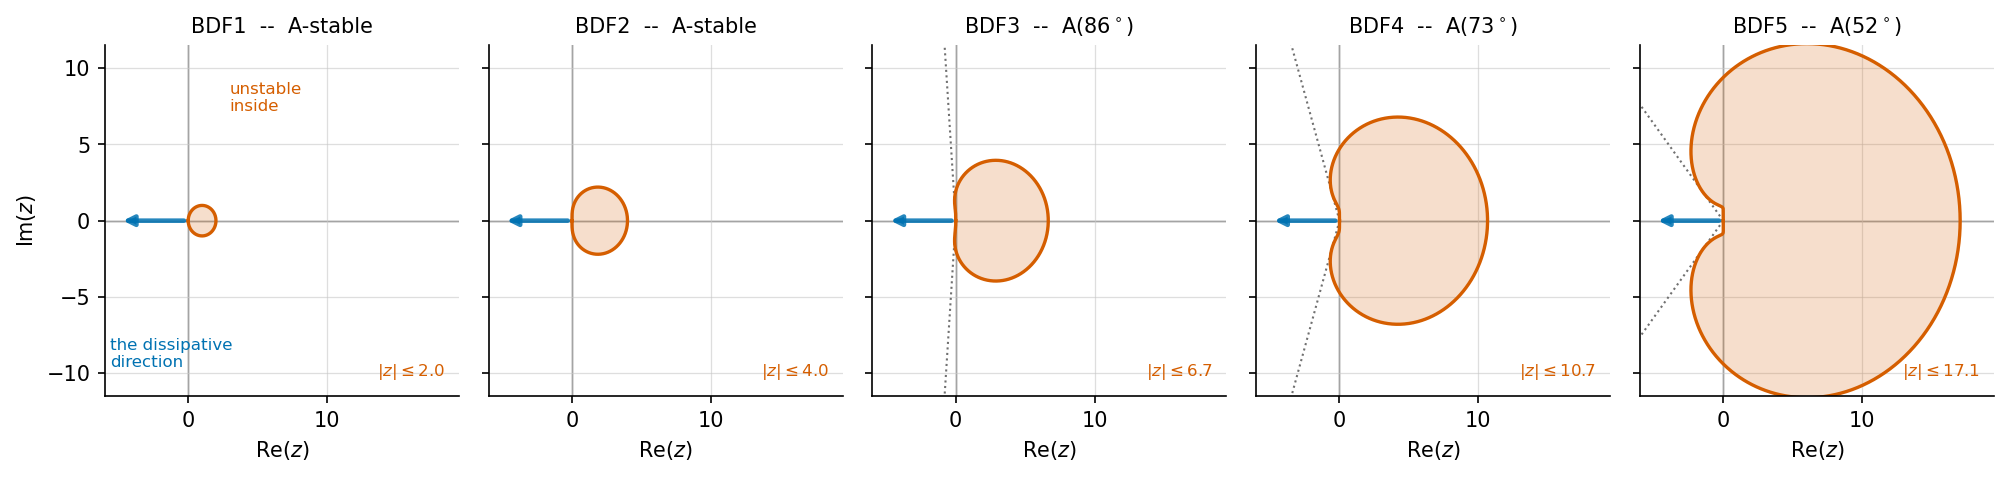

In [10]:
from IPython.display import Image
# The figure below is the output of this call, saved to the repository because
# the A(alpha) angle in each panel title is found by root finding and may take
# minutes to compute. Uncomment to regenerate it.
# demos.plot_bdf_stability_regions()[0].savefig(
#     'data/02b_stiffness/bdf_stability_regions.png', dpi=150, bbox_inches='tight')

Image(filename='data/02b_stiffness/bdf_stability_regions.png')

## What parameter set can reach the unstable region

> **Every dissipative effect lies on the negative real axis**

> **Only convection and strong gradients** may result in eigenvalues with imaginary part and may be inside the unstable region

</details>

<details>
<summary><b>Click to learn more: why each terms eigenvalues land where they do</b></summary>

Split the Jacobian into a symmetric and a skew-symmetric part, $J = H + S$ with $H = \tfrac12(J + J^{\top})$ and $S = \tfrac12(J - J^{\top})$. **Bendixson's theorem** then bounds the two directions separately:

$$\lambda_{\min}(H) \;\le\; \mathrm{Re}(\lambda) \;\le\; \lambda_{\max}(H), \qquad \mathrm{Im}(\lambda) \in \text{range of } \tfrac{1}{i}S .$$

The symmetric part decides how far **left** an eigenvalue sits; the skew part decides how far **off the axis**. Everything below follows from which of the two a given term contributes to.

**Diffusion is self-adjoint.** $\int u\,\partial_z^2 v = \int v\,\partial_z^2 u$, so the discretized operator is a symmetric matrix, and symmetric real matrices have real eigenvalues. Negative semi-definite, so they are non-positive. This covers axial dispersion and pore diffusion.

**Exchange and relaxation are symmetrizable.** Film transfer between bulk and pore liquid is

$$\begin{pmatrix}-a & a\\ b & -b\end{pmatrix},$$

whose rows sum to zero because material is conserved. Its eigenvalues are $0$ and $-(a+b)$, both real. The same holds for any network of positive exchange rates: a positive diagonal rescaling makes it symmetric.

**Adsorption is the same structure.** Linearizing the binding flux with $A = \partial F/\partial c$ and $B = -\partial F/\partial q$, the block for one component at one node is

$$J = \begin{pmatrix}-\beta A & \beta B\\ A & -B\end{pmatrix}, \qquad \det J = \beta A B - \beta A B = 0 .$$

The determinant vanishes because binding conserves $c + q/\beta$. One eigenvalue is therefore exactly zero — the conserved combination — and the other is the trace, $-(\beta A + B)$: real, negative, and equal to the rate the table reports. Evaluating this numerically for *competitive* three component Langmuir, where the components fight over the same sites, gives a 6×6 block with eigenvalues $-1.59$, $-1.29$, $-1.14$ and three exact zeros, with a largest imaginary part of $0$.

**Particle size enters twice, and both are of this kind.** Film transfer scales as $3k_f/r_p$, the specific surface area, and pore diffusion as $D_p/\Delta r^2$. Shrinking a particle therefore pushes real eigenvalues further left and contributes nothing at all to the skew part — which is why the particle study found it free.

**Convection is the exception, because the first derivative is anti-self-adjoint.** $\int u\,\partial_z v = -\int v\,\partial_z u$, so a central discretization is a *skew* matrix, and real skew matrices have **purely imaginary** eigenvalues: rotation without decay. Upwinding adds artificial diffusion, which is to say a symmetric negative part, and that is what moves the spectrum onto the circle through the origin drawn in the figure.

**Where the argument ends.** It rests on the dissipative terms being symmetrizable, which needs positive rates and something conserved. A reaction *network with a cycle and no detailed balance* — $X_0 \to X_1 \to \dots \to X_0$ — satisfies neither. Its Jacobian is circulant, and its eigenvalues sit on a circle at $90^\circ - 180^\circ/N$ from the negative real axis, which from six species on is outside the sector BDF5 covers at every magnitude. The cyclic reaction study drives a stirred tank there on purpose, and finds the only stability-limited behaviour in this chapter — over a window of step sizes, exactly as the bounded island predicts. A single reversible reaction, as in the reaction study, cannot do this.

</details>

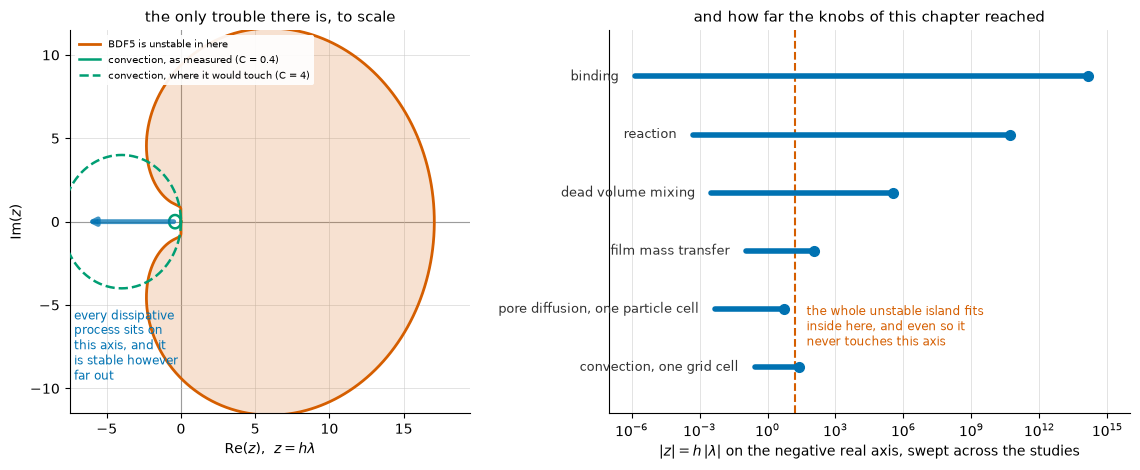

In [6]:
import utility.stiffness_demos as demos

demos.plot_where_the_eigenvalues_go();

**Every dissipative process puts its eigenvalue on the negative real axis**: binding relaxation, film transfer, pore and axial diffusion, reactions, a stirred dead volume. On that axis BDF is stable at *any* magnitude. The knobs of this chapter pushed eigenvalues out to $|z| \approx 10^{14}$, which is not closer to trouble but a hundred trillion times further from it.

**Convection is the one operator that leaves the axis**, because a first derivative is anti-self-adjoint. Upwinding puts its spectrum on a circle through the origin, and that circle *does* reach the unstable region: at a Courant number of about 4.

## The one case that does cost: convection on a fine grid

Everything so far said that stiffness is free. This is the exception, and it is worth seeing precisely what it is and what it is not.

The setting is the steep-front study of **[Stiffness 3b — Steep fronts DG](<stiffness/Stiffness 3b - Steep fronts DG.ipynb>)**: pure transport, a step injection, and three knobs — how **sharp** the front is (axial dispersion), how many **unknowns** pay for it (nodes), and how those unknowns are **arranged** (polynomial degree). Every row below is a slider position in that notebook, so each `BDF steps` entry can be reproduced there.

**Fix the system size at 256 nodes and move only the arrangement.** Same number of unknowns, same physics; only the shape of the convection operator changes.

| degree | elements | BDF steps at $Pe = 1.1\cdot10^{3}$ | BDF steps at $Pe = 1.1\cdot10^{7}$ | oscillation | nodal convection rate |
|---|---|---|---|---|---|
| FV (WENO) | 256 | 1833 | 5336 | 0.00 % | 2.9 $\mathrm{s^{-1}}$ |
| P1 | 128 | 1877 | 3926 | 6.5 % | 1.5 $\mathrm{s^{-1}}$ |
| P3 | 64 | 1920 | 6254 | 9.7 % | 6.5 $\mathrm{s^{-1}}$ |
| P7 | 32 | 1981 | 9401 | 10.4 % | 17.8 $\mathrm{s^{-1}}$ |
| **P15** | **16** | **1975** | **10029** | **10.3 %** | **40.9 $\mathrm{s^{-1}}$** |

Read the two step columns against each other. **Against a mild front the arrangement is free:** 1833 to 1981 steps across the whole sweep, a spread of 8 %, even though the nodal convection rate rises by a factor of 28 along the way. **Against a sharp front it is not:** the same degrees now cost 3926 to 10029 steps, and P15 takes **2.6 times** the steps of P1 for exactly the same number of unknowns.

**And refining the grid pays twice.** At P3, against the sharp front:

| nodes | elements | BDF steps |
|---|---|---|
| 64 | 16 | 2518 |
| 128 | 32 | 3934 |
| 256 | 64 | 6254 |
| 512 | 128 | 11742 |

Eight times the unknowns costs **4.7 times the steps** — and each of those steps is itself a solve of a system eight times larger.

> **This is the only place in the chapter where the grid and convection together make a simulation genuinely expensive.** Not because anything became unstable, but because a front narrower than the element carrying it cannot be represented, the polynomial answers with an oscillation instead, and the integrator then spends its steps resolving a feature that is not in the model.

<details>
<summary><b>Click to learn more: why the Courant number is the wrong thing to blame</b></summary>

The natural suspicion, straight after the stability picture above, is that these runs are being squeezed by the $C \approx 4$ circle. They are not, and the measurement says so three times over.

| run | median $C$ | 95th pct $C$ | error test failures | mean BDF order | BDF steps |
|---|---|---|---|---|---|
| P1, $Pe = 1.1\cdot10^{7}$ | 0.037 | 0.067 | 0 | 4.96 | 3926 |
| P3, $Pe = 1.1\cdot10^{7}$ | 0.116 | 0.116 | 2 | 4.97 | 6254 |
| P7, $Pe = 1.1\cdot10^{7}$ | 0.176 | 0.285 | 2 | 4.98 | 9401 |
| P15, $Pe = 1.1\cdot10^{7}$ | 0.291 | 0.525 | 0 | 4.98 | 10029 |
| P15, $Pe = 1.1\cdot10^{3}$ | 1.53 | 4.96 | 1 | 4.94 | **1975** |

**Nothing is near the stability boundary while it matters.** The mean BDF order is 4.94 to 4.98 in every run — the integrator sits at order five from beginning to end — and the local error test fails between **zero and two times** in up to ten thousand steps. An integrator fighting a stability limit looks nothing like this: it drops its order and fails error tests repeatedly, which is exactly what the explicit method in section 1 did.

**The Courant number runs the wrong way.** The *cheapest* run in the table is the one with the *highest* Courant number: P15 against the mild front sustains $C = 1.5$, reaches $C = 5.0$ at the 95th percentile — past the critical circle — and still finishes in **1975** steps. The most expensive run sustains $C = 0.29$ and takes five times as many. Cost here is not a function of $C$ at all.

Single steps do reach $C \approx 10^{3}$ in every one of these runs. Those are the last steps, after the column has reached steady state: a convection operator acting on a flat profile excites nothing, so the circle is irrelevant there. This is why the sustained Courant number, not the largest one, is the number worth quoting.

**What the steps actually buy is the oscillation.** At $Pe = 1.1\cdot10^{7}$ the front is **0.7 % of one P15 element** wide. No polynomial of degree 15 can represent that, so the element answers with a wiggle of about 10 % of the feed, and the error control spends its steps tracking it. WENO is monotone and has no such failure mode: it smears the front, leaves 0.00 % oscillation, and stays cheaper than every DG degree above P1.

So the honest summary is not "convection is stiff". It is: **a grid too coarse for your front is not merely inaccurate, it is also slow**, and refining the grid is the fix for both — which is exactly what the first row of the table in Act 5 says.

</details>

# Key take-aways

- stiffness is why CADET uses **implicit time integration**
- **stiffness usually** does **not affect the simulation** due to the stable implicit time integration
- implicit step size is **driven by accuracy, not stability!** Thus, time integration tolerances should be selected to match the desired accuracy, otherwise implicit time integration is expensive
- **compute cost** is moved to solving a **nonlinear system**, for which **Newtons method** is used
- some very **convection dominated problems** may still be compute heavy with **increased number of time steps**